<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/02_fundamental-concepts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 2: Fundamental Concepts
## How do machines learn?

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

> The book's Chapter 2 is conversational and has **no code**. To make the ideas tangible, the cells below are **my own small demos** (marked *Hands-on*). They are not reproductions of book code; they exist so each concept can be seen running.

---
## What is deep learning?

Deep learning is a *subset* of machine learning, which is itself a subset of the wider goal of artificial intelligence. In practice, deep learning means **training artificial neural networks**, a family of algorithms loosely inspired by the brain, to solve tasks in vision (images), natural language (text), and speech (audio).

Not all of it chases "general AI". Most real use is narrow and practical.

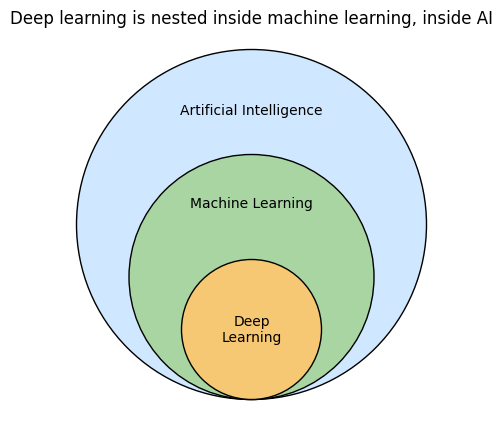

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(5, 5))
# (radius, centre_y, label_y, label, colour): circles share the same bottom edge
for r, cy, ly, label, col in [(1.0, 0.0, 0.65, "Artificial Intelligence", "#cfe8ff"),
                              (0.7, -0.3, 0.12, "Machine Learning", "#a8d5a2"),
                              (0.4, -0.6, -0.6, "Deep\nLearning", "#f7c873")]:
    ax.add_patch(Circle((0, cy), r, color=col, ec="k"))
    ax.text(0, ly, label, ha="center", va="center", fontsize=10)
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Deep learning is nested inside machine learning, inside AI")
plt.show()

---
## What is machine learning?

A machine-learning system gets better at a task **without being explicitly programmed for it**. The book's shorthand is *"monkey see, monkey do"*: the machine watches a pattern and imitates it, directly or indirectly. The direct kind is **supervised** learning; the indirect kind is **unsupervised** learning.

---
## Supervised machine learning

**Supervised learning transforms one dataset into another.** You show the algorithm many pairs of *(what you know → what you want to know)* and it learns to imitate the mapping.

Examples: pixels → "is there a cat?", past liked movies → recommended movies, Monday prices → Tuesday prices.

It is the workhorse of applied AI: even unsupervised methods are often used mainly to *help* a supervised model.

**Hands-on 1: a supervised mapping.** We invent *Monday → Tuesday* prices, then let a single "knob" find the relationship by trial and error.

learned knob = 1.02  (true hidden rule = 1.02)


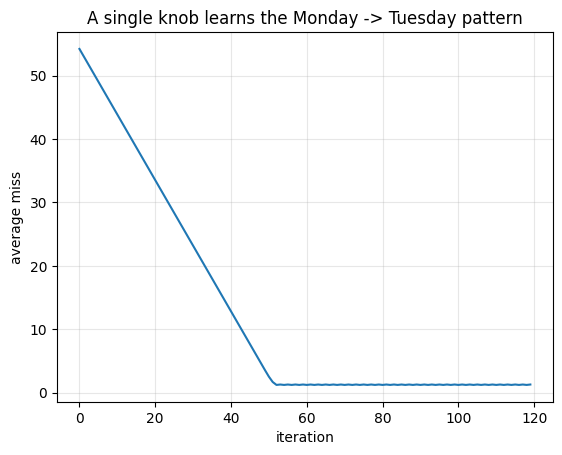

In [ ]:
import numpy as np
rng = np.random.default_rng(0)

monday  = rng.uniform(50, 150, size=30)                   # what we know
tuesday = 1.02 * monday + rng.normal(0, 1.5, size=30)     # what we want to know (hidden rule: x1.02 + noise)

knob, step = 0.5, 0.01
history = []
for it in range(120):
    pred = monday * knob                                   # 1) PREDICT
    miss = np.mean(np.abs(pred - tuesday))                 # 2) COMPARE
    history.append(miss)
    up   = np.mean(np.abs(monday * (knob + step) - tuesday))
    down = np.mean(np.abs(monday * (knob - step) - tuesday))
    knob += step if up < down else -step                   # 3) LEARN (turn the knob)

print(f"learned knob = {knob:.2f}  (true hidden rule = 1.02)")
plt.plot(history); plt.xlabel("iteration"); plt.ylabel("average miss")
plt.title("A single knob learns the Monday -> Tuesday pattern"); plt.grid(alpha=.3); plt.show()

The model's whole "knowledge" is one number. After enough turns it settles near the hidden rule (≈1.02), which shows what *supervised* (we gave it the answers) and *parametric* (one fixed knob) mean at once.

---
## Unsupervised machine learning

**Unsupervised learning groups your data.** Like supervised learning it transforms a dataset, but the output is *not known in advance*. Nobody supplies the right answer; you ask the algorithm to "find structure and report back".

The textbook case is **clustering**: a list of data points goes in, a list of cluster labels (1, 2, 3, ...) comes out. The labels are only numbers. *You* decide what a cluster means. (The book's example: `puppies, kittens` fall in one cluster that you might call "cute", and `pizza, hot dog, burger` in another that you might call "delicious".)

**Hands-on 2: clustering.** Stadium attendance (in thousands) is grouped into 3 clusters by a tiny k-means loop. We never tell the algorithm which game belongs where.

In [ ]:
fans = np.array([100, 50, 100, 99, 50, 10, 11], dtype=float)
centers = np.array([10.0, 50.0, 100.0])

for _ in range(10):
    labels = np.argmin(np.abs(fans[:, None] - centers[None, :]), axis=1)
    centers = np.array([fans[labels == k].mean() if (labels == k).any() else centers[k] for k in range(3)])

for f, l in zip(fans, labels):
    print(f"{f:5.0f}k fans -> cluster {l}")
print("cluster centres:", centers.round(1))

  100k fans -> cluster 2
   50k fans -> cluster 1
  100k fans -> cluster 2
   99k fans -> cluster 2
   50k fans -> cluster 1
   10k fans -> cluster 0
   11k fans -> cluster 0
cluster centres: [10.5 50.  99.7]


The output is just a label per row. Naming the groups ("quiet / average / packed") is our job, not the algorithm's.

---
## Parametric vs. nonparametric learning

This is a *second, independent* way to split the same algorithms, so every method lands in one cell of a 2×2 grid:

| | Parametric | Nonparametric |
|---|---|---|
| **Supervised** | ✓ | ✓ |
| **Unsupervised** | ✓ | ✓ |

- **Parametric**: a **fixed number of parameters** (knobs). Learning = adjusting them, which is a form of trial-and-error search.
- **Nonparametric**: the number of parameters **grows with the data**. Learning is mostly *counting*.

Analogy from the book: a baby tries the square peg in every hole until it fits (parametric); an older child counts four sides and looks for the four-sided hole (nonparametric). Deep learning belongs to the parametric camp.

---
## Supervised parametric learning

*Oversimplified: trial-and-error learning with knobs.* Data flows in, the knobs' current angles shape the output, and a prediction comes out. After learning the truth, the algorithm nudges the knobs.

### The three steps
1. **Predict**: feed the data through the machine to get a number (e.g. "98% chance the team wins").
2. **Compare**: set the prediction against what actually happened (the team lost, so the ideal prediction was 0%; we missed by 98%).
3. **Learn**: use *how much we missed* and *what the input was* to turn each knob. Each knob is a sensitivity to one kind of input, so learning changes how strongly each input counts.

This predict → compare → learn loop is the skeleton of the whole book. Hands-on 1 above is a miniature version of it.

---
## Unsupervised parametric learning

Same idea, applied to grouping. The model keeps several knobs *per group*; for a data point each group's knobs output a number between 0 and 1: the probability that the point belongs to that group.

**Hands-on 3: group-membership probabilities.** We reuse the cluster centres from Hands-on 2 and turn the distance to each centre into a probability with a softmax.

In [ ]:
def membership(x, centers, scale=8.0):
    scores = -np.abs(x - centers) / scale          # closer centre -> higher score
    e = np.exp(scores - scores.max())
    return e / e.sum()

for x in [100, 55, 12]:
    p = membership(x, centers)
    print(f"{x:>4}k fans -> P(cluster 0,1,2) = {np.round(p, 3)}")

 100k fans -> P(cluster 0,1,2) = [0.    0.002 0.998]
  55k fans -> P(cluster 0,1,2) = [0.007 0.986 0.007]
  12k fans -> P(cluster 0,1,2) = [0.99 0.01 0.  ]


A 100k crowd is almost certainly cluster 2, while 55k leans to cluster 1. The model is parametric because `centers` and `scale` are a fixed set of numbers, whatever the size of the dataset.

---
## Nonparametric learning

*Oversimplified: counting-based methods.* Here the parameters **are the counts**, so more categories mean more parameters. The book's example counts how often each traffic-light position is followed by cars going.

**Hands-on 4: counting model, and why its size depends on the data.**

In [ ]:
from collections import defaultdict

def fit_counts(observations):
    counts = defaultdict(lambda: [0, 0])          # [times cars went, total times]
    for lamp, went in observations:
        counts[lamp][0] += went
        counts[lamp][1] += 1
    return counts

obs3 = [("middle", 1), ("middle", 1), ("right", 1), ("right", 0), ("left", 0), ("left", 0)]
m = fit_counts(obs3)
for lamp, (went, total) in m.items():
    print(f"{lamp:6s}: P(go) = {went}/{total} = {went/total:.0%}")
print("parameters with 3 lamp types:", len(m))

obs5 = obs3 + [("far-left", 1), ("far-right", 0)]
print("parameters with 5 lamp types:", len(fit_counts(obs5)))

middle: P(go) = 2/2 = 100%
right : P(go) = 1/2 = 50%
left  : P(go) = 0/2 = 0%
parameters with 3 lamp types: 3
parameters with 5 lamp types: 5


Compare with Hands-on 1, where the model stayed one knob no matter how much data arrived. Here the model got bigger when new lamp types appeared. That growth is the defining trait of a nonparametric model. (Counts, weights and correlation coefficients are all just "parameters": numbers that describe a pattern.)

---
## Summary

- Every ML algorithm is **supervised or unsupervised** *and* **parametric or nonparametric**.
- Supervised = learn to predict one dataset from another. Unsupervised = cluster a dataset.
- Parametric = fixed knobs adjusted by trial and error. Nonparametric = parameters grow, usually through counting.
- **Deep learning = neural networks = parametric learning** (both supervised and unsupervised).
- Next chapter: build the *predict* step of a real neural network.